In [1]:
import os
import sys

# Add your module's directory (absolute path or relative path)
module_path = os.path.abspath(os.path.join('../src')) 
if module_path not in sys.path:
    sys.path.insert(0, module_path)


In [2]:
from bandit_walk import BanditWalk
from policy_metrics import probability_success, mean_return, play_episode
from display import print_policy, print_transitions, print_state_value_function

from bandit_slippery_walk import BanditSlipperyWalk
from models import Environment
from dp import policy_improvement, policy_evaluation, policy_iteration

import random
import numpy as np

In [3]:
bandit_walk_1 = BanditSlipperyWalk(n_states=7, start=2, slip_prob=0.5)

In [4]:
bandit_walk_1.goal

6

In [5]:
bandit_walk_1.state

2

In [6]:
"""Russell & Norvig's 4x3 Gridworld (AIMA Fig. 17.1).

Classic layout (x right, y up; start bottom-left):

        (1,3)   (2,3)   (3,3)   (4,3)  +1
        (1,2)   (2,2)   (3,2)   (4,2)  -1
        (1,1)S  (2,1)X  (3,1)   (4,1)      X = blocked cell

Motion model: intended direction with prob 0.8, each of the two
perpendicular directions with prob 0.1 (matching AIMA). Moves that would
walk off the board or into the blocked cell leave the agent in place
("bump"); those stay-branches are merged with any other branch landing on
the same state.

Everything is configurable: grid size, start, terminal rewards,
blocked cells, living reward, and slip probabilities.
"""

from env_core import EnvCore
from models import Action, ActionResult

UP, DOWN, LEFT, RIGHT = 0, 1, 2, 3

_DELTAS = {                  # (dx, dy); y increases upward (R&N convention)
    UP:    (0,  1),
    DOWN:  (0, -1),
    LEFT:  (-1, 0),
    RIGHT: (1,  0),
}

_SYMBOLS = {UP: "^", DOWN: "v", LEFT: "<", RIGHT: ">"}


class GridWorld(EnvCore):

    def __init__(self, n_rows=3, n_cols=4, start_xy=(1, 1),
                 terminal_rewards=None, blocked_xy=None,
                 living_reward=-0.04, slip_probs=(0.1, 0.8, 0.1),
                 seed=None):
        """terminal_rewards: dict[(x, y), float] of absorbing outcomes.
        blocked_xy       : iterable of (x, y) cells that are walls.
        slip_probs       : (prob perpendicular-left, prob intended,
                            prob perpendicular-right), must sum to 1.
        """
        super().__init__(seed=seed)

        self.n_rows = int(n_rows)
        self.n_cols = int(n_cols)
        if self.n_rows < 2 or self.n_cols < 2:
            raise ValueError("grid must be at least 2x2")
        self.n_states = self.n_rows * self.n_cols

        self.start_state = self._index(*start_xy)
        self.slip_probs = tuple(float(p) for p in slip_probs)

        # Defaults reproduce the textbook world exactly.
        if terminal_rewards is None:
            terminal_rewards = {(self.n_cols, self.n_rows): 1.0,   # (4,3) +1
                                (self.n_cols, self.n_rows - 1): -1.0}  # (4,2) -1
        if blocked_xy is None:
            blocked_xy = {(2, 1)}

        self._terminals = {self._index(x, y): float(r)
                           for (x, y), r in terminal_rewards.items()}
        self._blocked = {self._index(x, y) for (x, y) in blocked_xy}
        self.living_reward = float(living_reward)
        self.step_reward = self.living_reward        # name shared with other envs

        self._verify()
        self._build_action_map()
        self._build_transitions()
        self.reset()

    # ------------------------------------------------------------ helpers
    def _index(self, x: int, y: int) -> int:
        """(x, y) with y upward -> row-major index (y=1 is the bottom row)."""
        return (y - 1) * self.n_cols + (x - 1)

    def _xy(self, s: int) -> tuple[int, int]:
        return (s % self.n_cols) + 1, (s // self.n_cols) + 1

    # ------------------------------------------------------------ configuration
    def _verify(self):
        n = self.n_states
        if not 0 <= self.start_state < n:
            raise ValueError(f"start out of range: got {self._xy(self.start_state)}")

        for s, r in self._terminals.items():
            if not 0 <= s < n:
                raise ValueError(f"terminal {self._xy(s)} out of range")
            if s in self._blocked:
                raise ValueError(f"terminal {self._xy(s)} is also blocked")
        if not self._terminals:
            raise ValueError("need at least one terminal state")
        if self.start_state in self._terminals:
            raise ValueError("start must not be a terminal state")
        if self.start_state in self._blocked:
            raise ValueError("start must not be blocked")

        for s in self._blocked:
            if not 0 <= s < n:
                raise ValueError(f"blocked cell {self._xy(s)} out of range")

        if len(self.slip_probs) != 3:
            raise ValueError("slip_probs must be (perp-left, intended, perp-right)")
        if any(p < 0 for p in self.slip_probs):
            raise ValueError("slip_probs must be non-negative")
        if abs(sum(self.slip_probs) - 1.0) > 1e-9:
            raise ValueError(f"slip_probs must sum to 1, got {sum(self.slip_probs)}")

    def _build_action_map(self):
        self._actions: dict[int, Action] = {
            UP:    Action("Up",    UP,    "^"),
            DOWN:  Action("Down",  DOWN,  "v"),
            LEFT:  Action("Left",  LEFT,  "<"),
            RIGHT: Action("Right", RIGHT, ">"),
        }
        self._actions_by_name = {a.name: a.code for a in self._actions.values()}

    # ------------------------------------------------------------ transitions
    def _build_transitions(self):
        p_left, p_intended, p_right = self.slip_probs
        P = {}

        for s in range(self.n_states):
            P[s] = {}
            for code in self._actions:
                # Absorbing: terminals and (never-used) blocked cells.
                if s in self._terminals or s in self._blocked:
                    P[s][code] = [ActionResult(1.0, s, 0.0, True)]
                    continue

                x, y = self._xy(s)
                dx, dy = _DELTAS[code]

                # Intended + the two perpendicular directions (rotate 90°).
                moves = [((dy, -dx), p_left),
                         ((dx,  dy), p_intended),
                         ((-dy,  dx), p_right)]

                branches: dict[tuple, float] = {}
                for (m_dx, m_dy), prob in moves:
                    if prob <= 0.0:
                        continue
                    nx, ny = x + m_dx, y + m_dy

                    # Bump: off the grid, or into a blocked cell -> stay.
                    if not (1 <= nx <= self.n_cols and 1 <= ny <= self.n_rows) \
                            or self._index(nx, ny) in self._blocked:
                        nxt = s
                    else:
                        nxt = self._index(nx, ny)

                    if nxt in self._terminals:
                        reward, done = self._terminals[nxt], True
                    else:
                        reward, done = self.living_reward, False

                    key = (nxt, reward, done)
                    branches[key] = branches.get(key, 0.0) + prob

                P[s][code] = [ActionResult(p, nxt, r, d)
                              for (nxt, r, d), p in branches.items()]
        self._P = P

    # ---------------------------------------------------------------- display
    def display(self, show_indices: bool = True, show_legend: bool = True) -> None:
        """Board in R&N orientation (top row first, bottom-left = start)."""
        if show_legend:
            print("Legend: S=start  G=+1 goal  H=-1 hole  X=blocked  F=floor  A=agent")

        def cell(s: int) -> str:
            if s in self._blocked:
                return "X"
            if s in self._terminals:
                return "G" if s == self.goal else "H"
            if s == self.start_state:
                return "S"
            return "F"
        return self._render(lambda s: cell(s), show_indices)

    def render_policy(self, pi) -> None:
        """Draw a policy on the grid, R&N orientation."""
        def core(s: int) -> str:
            if s in self._blocked:
                return "X"
            if s in self._terminals:
                return "G" if s == self.goal else "H"
            return _SYMBOLS[pi(s)]
        self._render(lambda s: core(s), show_indices=False)

    def render_values(self, V, prec: int = 3) -> None:
        """Draw a value function on the grid, R&N orientation."""
        def core(s: int) -> str:
            if s in self._blocked:
                return "X"
            if s in self._terminals:
                return "G" if s == self.goal else "H"
            return f"{V[s]:.{prec}f}"
        self._render(lambda s: core(s), show_indices=False)

    def _render(self, core_fn, show_indices: bool) -> None:
        """Shared painter: iterate rows top -> bottom, cells left -> right."""
        for y in range(self.n_rows, 0, -1):
            row = [self._index(x, y) for x in range(1, self.n_cols + 1)]
            print("| " + " | ".join(f"{core_fn(s):^7}" for s in row) + " |")
            if show_indices:
                print("| " + " | ".join(f"({self._xy(s)[0]},{self._xy(s)[1]})".center(7)
                                        for s in row) + " |")

    # ------------------------------------------------------------ read-only api
    @property
    def P(self):
        return self._P

    @property
    def actions(self):
        return self._actions

    @property
    def state(self):
        return self._state

    @property
    def display_cols(self):
        return self.n_cols           # lets display.py lay the grid out in 2D

    @property
    def terminal_rewards(self):
        return dict(self._terminals)

    @property
    def blocked(self):
        return set(self._blocked)

    @property
    def goal(self) -> int:
        """The +1 terminal (by convention: the highest-reward terminal)."""
        return max(self._terminals, key=self._terminals.get)

    @property
    def holes(self) -> list[int]:
        """Non-goal terminals (so dp.policy_evaluation skips them)."""
        return [s for s in self._terminals if s != self.goal]

In [7]:
bandit_walk_1 = GridWorld(seed=0)

In [8]:
bandit_walk_1.actions

{0: Action(name='Up', code=0, symbol='^'),
 1: Action(name='Down', code=1, symbol='v'),
 2: Action(name='Left', code=2, symbol='<'),
 3: Action(name='Right', code=3, symbol='>')}

In [9]:
UP, DOWN, LEFT, RIGHT = 0, 1, 2, 3

# policy = lambda s: {0: LEFT, 1: RIGHT, 2: LEFT, 3: RIGHT, 4: LEFT, 5: RIGHT}[s]
policy = lambda s: {0: RIGHT ,1: RIGHT ,2: RIGHT ,3: RIGHT ,4: UP ,5: UP ,6: UP ,7: UP ,8: UP ,9: LEFT ,10: LEFT ,11: LEFT}[s]

In [10]:
import numpy as np


def decay_schedule(init_value, min_value, decay_ratio, max_steps=5000, log_start=-2, log_base=10):
    decay_steps = max(min(int(max_steps * decay_ratio), max_steps), 2)
    rem_steps = max_steps - decay_steps
    values = np.logspace(log_start, 0, decay_steps, base=log_base, endpoint=True)[::-1]
    values = (values - values.min()) / (values.max() - values.min())
    values = (init_value - min_value) * values + min_value
    return np.pad(values, (0, rem_steps), 'edge')


def evmc(env, policy, gamma=0.99, alpha=None,
         init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5,
         n_episodes=1000, first_visit=False,
         max_steps=5000, on_truncate='skip', collect_targets=True):
    """Every-visit MC prediction of V(s), with episode cap + V tracking.

    Returns (V, V_track, targets).

    on_truncate:
      'skip' -> discard episodes that hit max_steps before terminating
                (keeps MC returns unbiased; episodes are dropped, not used)
      'use'  -> update with the partial (truncated) return
                (biased, but you still make progress on long-horizon tasks)

    collect_targets=False (recommended for long episodes) skips building the
    targets dict so memory stays O(n_states * n_episodes), not O(total visits).
    """
    nS = env.n_states
    V = np.zeros(nS, dtype=np.float64)
    V_track = np.zeros((n_episodes, nS), dtype=np.float64)
    targets = {s: [] for s in range(nS)} if collect_targets else None
    N = np.zeros(nS, dtype=np.int64)

    # ---- step-size mode -----------------------------------------------
    if alpha is None:
        mode, alphas = 'mean', None
    elif isinstance(alpha, str) and alpha == 'decay':
        mode = 'decay'
        alphas = decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes)
    elif callable(alpha):
        mode = 'decay'
        alphas = np.array([float(alpha(e, n_episodes)) for e in range(n_episodes)])
    else:
        mode = 'const'
        alphas = np.full(n_episodes, float(alpha))

    n_used = 0
    for e in range(n_episodes):
        # ---- collect ONE episode, HARD-CAPPED at max_steps ------------
        states, rewards = [], []
        s_t = env.reset()
        if s_t is None:
            s_t = env.state                     # fallback for state-setting envs

        done, steps = False, 0
        while not done and steps < max_steps:
            action = policy(s_t) if callable(policy) else policy[s_t]
            result = env.step(action)
            states.append(s_t)
            rewards.append(result.reward)
            s_t = result.next_state
            done = result.done
            steps += 1

        if not states:
            V_track[e] = V.copy()
            continue

        # MC needs complete returns -> drop truncated episodes (default)
        if not done and on_truncate == 'skip':
            V_track[e] = V.copy()
            continue

        # ---- returns-to-go, O(T) backward sweep ------------------------
        returns = np.empty(len(states))
        G = 0.0
        for i in range(len(states) - 1, -1, -1):
            G = rewards[i] + gamma * G
            returns[i] = G

        # ---- updates (first-visit or every-visit) ----------------------
        seen = set()
        for s, Gs in zip(states, returns):
            if first_visit:
                if s in seen:
                    continue
                seen.add(s)
            if collect_targets:
                targets[s].append(Gs)
            if mode == 'mean':
                N[s] += 1
                V[s] += (Gs - V[s]) / N[s]      # sample mean (true EVMC)
            else:
                V[s] += alphas[e] * (Gs - V[s]) # decay/constant step-size
        V_track[e] = V.copy()
        n_used += 1

    print(f"[evmc] used {n_used}/{n_episodes} episodes "
          f"({n_episodes - n_used} skipped: hit max_steps={max_steps})")
    return V.copy(), V_track, targets

In [11]:



def fvmc(env, policy, gamma=0.99, alpha=None,
         init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5,
         n_episodes=5000, max_steps=200):
    """First-visit Monte Carlo prediction of V(s), with V tracking.

    Only the FIRST occurrence of each state in an episode is used for the
    update. Returns are recorded/targeted for those first visits only.

    Returns (V, V_track, targets):
      - V       : final value function, shape (n_states,)
      - V_track : shape (n_episodes, n_states); V after each episode
      - targets : dict {state: [raw first-visit return-to-go per episode]}

    Step-size modes (alpha):
      - alpha=None       -> sample mean 1/N(s): canonical textbook FVMC
      - alpha='decay'    -> per-episode schedule init_alpha -> min_alpha
      - alpha=<float>    -> constant step-size (moving average)
      - alpha=<callable> -> custom per-episode alpha alpha(e, n_episodes)
    """
    nS = env.n_states
    V = np.zeros(nS, dtype=np.float64)
    V_track = np.zeros((n_episodes, nS), dtype=np.float64)
    targets = {s: [] for s in range(nS)}
    N = np.zeros(nS, dtype=np.int64)

    # ---- step-size mode (same options as evmc_updated) -----------------
    if alpha is None:
        mode, alphas = 'mean', None
    elif isinstance(alpha, str) and alpha == 'decay':
        mode = 'decay'
        alphas = decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes)
    elif callable(alpha):
        mode = 'decay'
        alphas = np.array([float(alpha(e, n_episodes)) for e in range(n_episodes)])
    else:
        mode = 'const'
        alphas = np.full(n_episodes, float(alpha))

    for e in range(n_episodes):
        # ---- collect one episode ---------------------------------------
        states, rewards = [], []
        s_t = env.reset()
        if s_t is None:
            s_t = env.state                     # fallback for state-setting envs

        done = False
        steps = 0
        while not done and steps < max_steps:
            action = policy(s_t) if callable(policy) else policy[s_t]
            result = env.step(action)
            states.append(s_t)
            rewards.append(result.reward)
            s_t = result.next_state
            done = result.done
            steps += 1
        if not states:                          # empty episode -> no update
            V_track[e] = V
            continue

        # ---- returns-to-go, O(T) backward sweep ------------------------
        returns = np.empty(len(states))
        G = 0.0
        for i in range(len(states) - 1, -1, -1):
            G = rewards[i] + gamma * G
            returns[i] = G

        # ---- FIRST-visit updates ---------------------------------------
        seen = set()
        for s, Gs in zip(states, returns):
            if s in seen:                       # skip repeat visits to s!
                continue
            seen.add(s)

            targets[s].append(Gs)               # first-visit return only
            if mode == 'mean':
                N[s] += 1
                V[s] += (Gs - V[s]) / N[s]      # sample mean (canonical FVMC)
            else:
                V[s] += alphas[e] * (Gs - V[s]) # decay/constant step-size

        V_track[e] = V                          # snapshot after episode e

    return V.copy(), V_track, targets

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl


def plot_v_track(V_track, log_x=False, title="State values across episodes",
                 figsize=(10, 6), cmap=None, line_alpha=0.9):
    """Plot estimated state value V(s) for every state vs. episode.

    - x-axis : episode number (1..n_episodes)
    - y-axis : estimated V(s) for that episode
    - each line = one state; color indicates the state (see legend)
    - log_x=True : switch x-axis to log scale.

    Note: episode 0 cannot be shown on a log axis (log(0) is undefined),
    so the log x-axis spans [1, n_episodes]; in linear mode it spans [0, n_episodes].
    """
    V_track = np.asarray(V_track, dtype=np.float64)
    n_episodes, n_states = V_track.shape
    episodes = np.arange(1, n_episodes + 1)

    # optional explicit colormap; defaults to matplotlib's cycle
    colors = None
    if cmap is not None:
        colors = mpl.colormaps.get_cmap(cmap)(np.linspace(0, 1, n_states))

    fig, ax = plt.subplots(figsize=figsize)
    for s in range(n_states):
        ax.plot(episodes, V_track[:, s],
                color=None if colors is None else colors[s],
                linewidth=1.6, alpha=line_alpha, label=f"State {s}")

    ax.set_xlabel("Episode")
    ax.set_ylabel("Estimated state value  V(s)")
    ax.set_title(title)
    ax.legend(title="State", loc="best", framealpha=0.9)
    ax.grid(True, alpha=0.3)

    if log_x:
        ax.set_xscale("log")
        ax.set_xlim(1, n_episodes)          # log axis can't include 0
    else:
        ax.set_xlim(0, n_episodes)

    fig.tight_layout()
    return fig, ax

[evmc] used 470/1000 episodes (530 skipped: hit max_steps=5000)
Targets: {0: [np.float64(-3.999751098104809), np.float64(-3.9997485839442515), np.float64(-3.9997460443881327), np.float64(-3.9997434791799322), np.float64(-3.9997408880605376), np.float64(-3.9997382707682196), np.float64(-3.9997356270386057), np.float64(-3.9997329566046522), np.float64(-3.9997302591966184), np.float64(-3.9997275345420387), np.float64(-3.999724782365696), np.float64(-3.9999875457897396), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999999999782), np.float64(-3.9999999752541893), np.float64(-3.9999999750042314), np.float64(-3.999999974751749), np.float64(-3.999999974496716), np

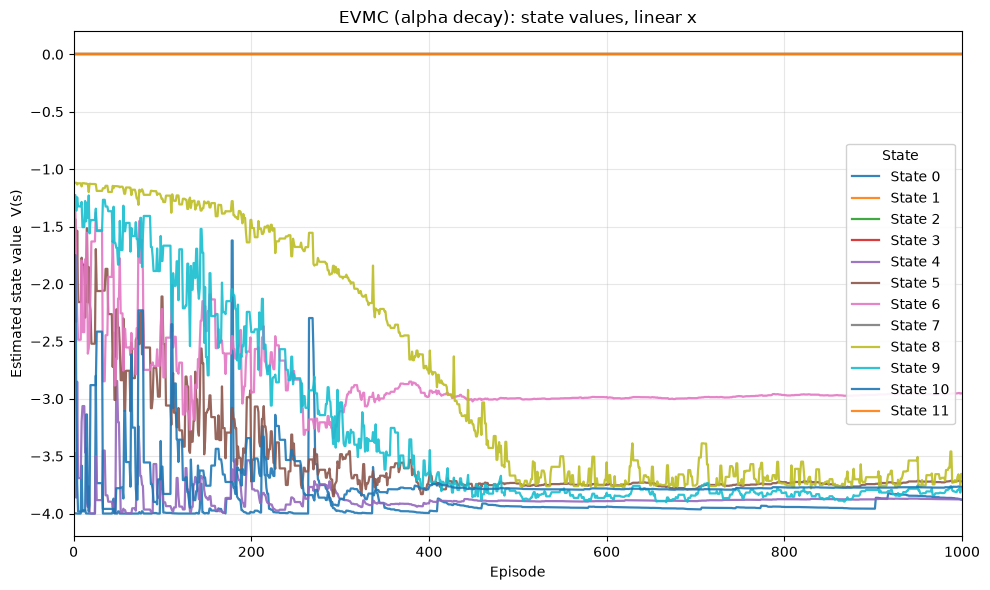

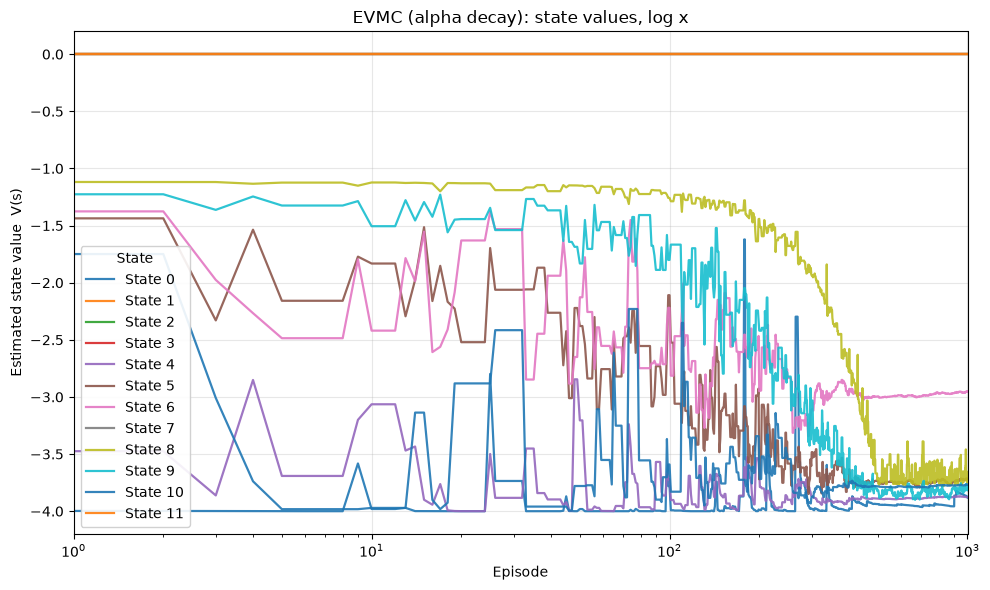

In [13]:
# Run EVMC with book-style alpha decay and grab the tracking array
V, V_track, targets = evmc(
    bandit_walk_1, policy,
    gamma=0.99, alpha='decay',
    init_alpha=0.5, min_alpha=1e-3, alpha_decay_ratio=0.5,
    n_episodes=1000, first_visit=False,
)

print("Targets:", targets)

# Linear x-axis
fig_lin, ax_lin = plot_v_track(V_track, log_x=False,
                               title="EVMC (alpha decay): state values, linear x")

# Log x-axis (episodes 1..5000)
fig_log, ax_log = plot_v_track(V_track, log_x=True,
                               title="EVMC (alpha decay): state values, log x")

plt.show()

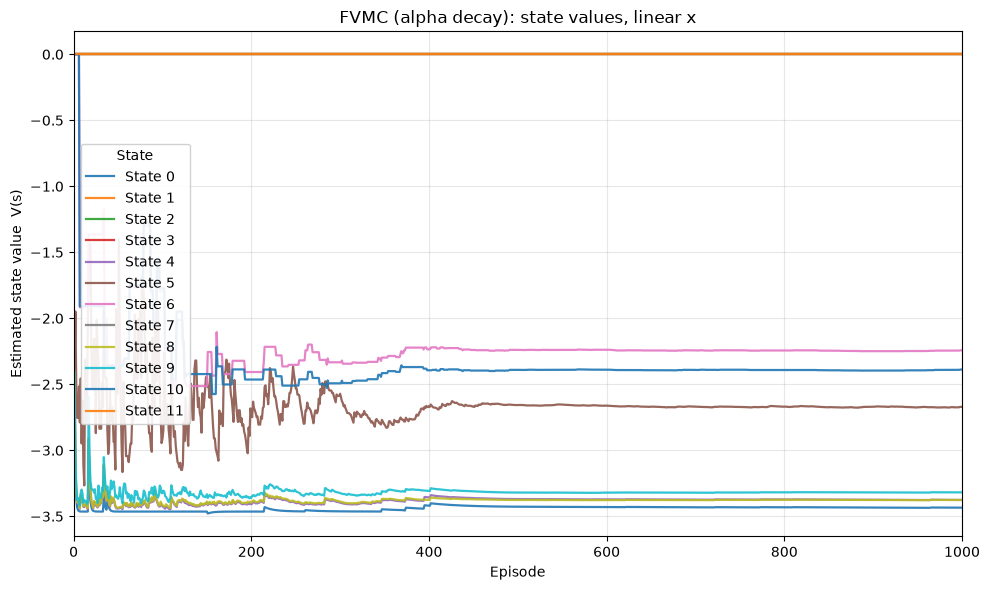

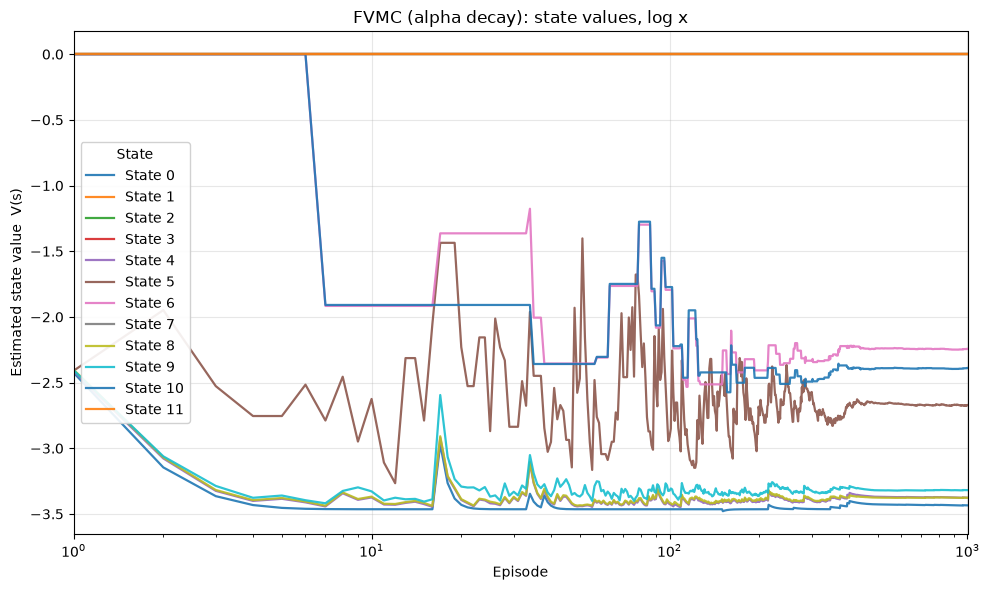

In [14]:
# Run EVMC with book-style alpha decay and grab the tracking array
V, V_track, targets = fvmc(
    bandit_walk_1, policy,
    gamma=0.99, alpha='decay',
    init_alpha=0.7, min_alpha=1e-3, alpha_decay_ratio=0.5,
    n_episodes=1000
)

# Linear x-axis
fig_lin, ax_lin = plot_v_track(V_track, log_x=False,
                               title="FVMC (alpha decay): state values, linear x")

# Log x-axis (episodes 1..5000)
fig_log, ax_log = plot_v_track(V_track, log_x=True,
                               title="FVMC (alpha decay): state values, log x")

plt.show()

Temporal Difference - TD algorithm

In [15]:
def td(env, policy, gamma=0.99, alpha=None,
       init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5,
       n_episodes=5000, max_steps=200):
    """TD(0) prediction of V(s), with alpha decay and V tracking.

    Returns (V, V_track):
      - V       : final value function, shape (n_states,)
      - V_track : shape (n_episodes, n_states); V after each episode

    Step-size modes (alpha):
      - alpha='decay'   -> per-episode schedule init_alpha -> min_alpha
      - alpha=<float>   -> constant step-size (default if None: 0.1)
      - alpha=<callable>-> custom per-episode alpha alpha(e, n_episodes)
    """
    nS = env.n_states
    V = np.zeros(nS, dtype=np.float64)
    V_track = np.zeros((n_episodes, nS), dtype=np.float64)

    # ---- step-size mode ------------------------------------------------
    if isinstance(alpha, str) and alpha == 'decay':
        alphas = decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes)
    elif callable(alpha):
        alphas = np.array([float(alpha(e, n_episodes)) for e in range(n_episodes)])
    else:
        if alpha is None:
            alpha = 0.1
        alphas = np.full(n_episodes, float(alpha))

    for e in range(n_episodes):
        s_t = env.reset()
        if s_t is None:
            s_t = env.state                     # fallback for state-setting envs

        done = False
        steps = 0
        while not done and steps < max_steps:   # max_steps actually used now
            action = policy(s_t) if callable(policy) else policy[s_t]
            result = env.step(action)
            next_state = result.next_state

            # --- TD(0) target ------------------------------------------
            # No bootstrap on the terminal transition: if the episode is
            # over, there is no V(s') term -- target is just the reward.
            td_target = result.reward
            if not result.done and next_state is not None:
                td_target += gamma * V[next_state]

            td_error = td_target - V[s_t]
            V[s_t] += alphas[e] * td_error

            done = result.done
            s_t = result.next_state
            steps += 1

        V_track[e] = V.copy()

    return V.copy(), V_track

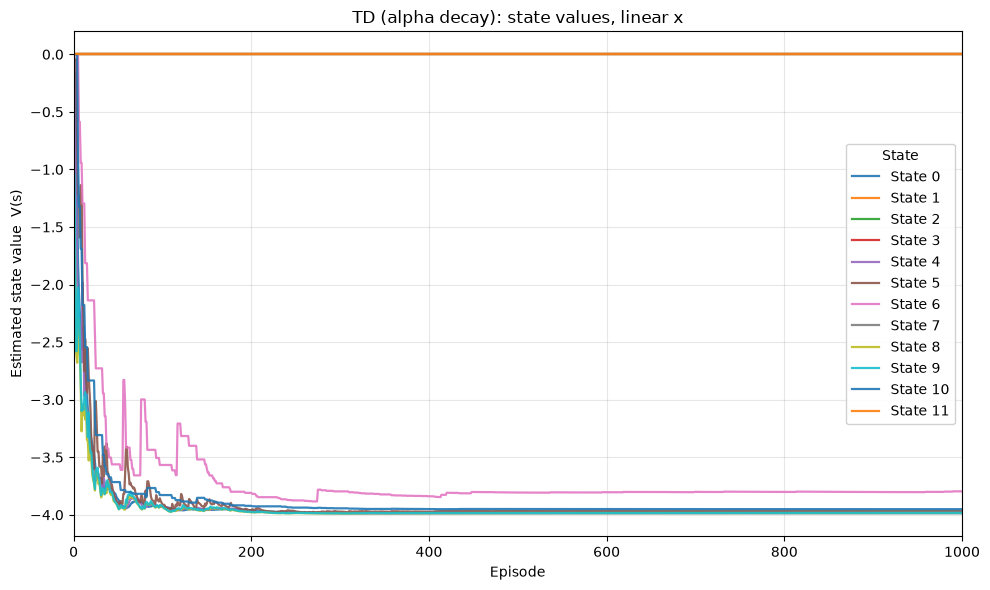

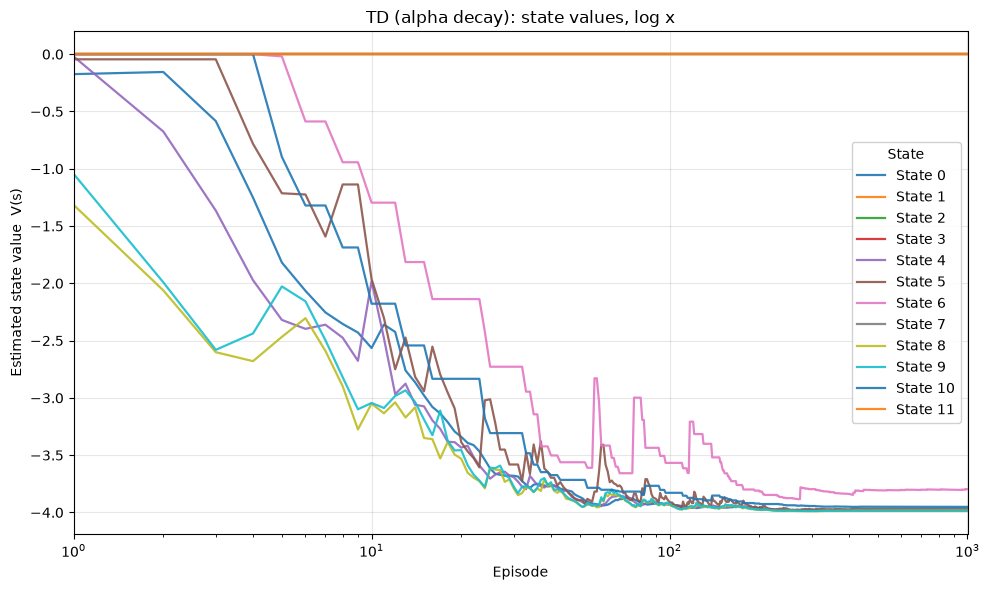

In [16]:
# Run EVMC with book-style alpha decay and grab the tracking array
# V, V_track, targets = td(
#     bandit_walk_1, policy,
#     gamma=0.99, alpha='decay',
#     init_alpha=0.7, min_alpha=1e-3, alpha_decay_ratio=0.5,
#     n_episodes=1000
# )

V, V_track = td(bandit_walk_1, policy, gamma=0.99, alpha='decay',
                   init_alpha=0.5, min_alpha=1e-3, alpha_decay_ratio=0.5,
                   n_episodes=1000)

# Linear x-axis
fig_lin, ax_lin = plot_v_track(V_track, log_x=False,
                               title="TD (alpha decay): state values, linear x")

# Log x-axis (episodes 1..5000)
fig_log, ax_log = plot_v_track(V_track, log_x=True,
                               title="TD (alpha decay): state values, log x")

plt.show()

In [17]:
import numpy as np


def decay_schedule(init_value, min_value, decay_ratio, max_steps, log_start=-2, log_base=10):
    decay_steps = max(min(int(max_steps * decay_ratio), max_steps), 2)
    rem_steps = max_steps - decay_steps
    values = np.logspace(log_start, 0, decay_steps, base=log_base, endpoint=True)[::-1]
    values = (values - values.min()) / (values.max() - values.min())
    values = (init_value - min_value) * values + min_value
    return np.pad(values, (0, rem_steps), 'edge')


def _make_alphas(alpha, init_alpha, min_alpha, alpha_decay_ratio, n_episodes):
    """Shared step-size schedule: 'decay' | callable | float (default 0.1)."""
    if isinstance(alpha, str) and alpha == 'decay':
        return decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes)
    if callable(alpha):
        return np.array([float(alpha(e, n_episodes)) for e in range(n_episodes)])
    if alpha is None:
        alpha = 0.1
    return np.full(n_episodes, float(alpha))


# ---------------------------------------------------------------------------
# n-step TD
# ---------------------------------------------------------------------------
def ntd(env, policy, gamma=0.99, n=3, alpha=None,
        init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5,
        n_episodes=5000, max_steps=200):
    """n-step TD prediction of V(s).

    G_t^(n) = R_{t+1} + g*R_{t+2} + ... + g^{n-1} R_{t+n} + g^n V(S_{t+n})
    V(S_t) <- V(S_t) + a [G_t^(n) - V(S_t)]

    Special cases:
      n=1              -> TD(0)
      n=None           -> full return (every-visit MC with the same alpha mode)
      t+n past episode end -> return truncates to the full episode return.

    Returns (V, V_track): V_track[e, s] = V(s) after episode e.
    """
    nS = env.n_states
    V = np.zeros(nS, dtype=np.float64)
    V_track = np.zeros((n_episodes, nS), dtype=np.float64)
    alphas = _make_alphas(alpha, init_alpha, min_alpha, alpha_decay_ratio, n_episodes)

    for e in range(n_episodes):
        # ---- collect one episode ---------------------------------------
        states, rewards = [], []
        s_t = env.reset()
        if s_t is None:
            s_t = env.state                     # fallback for state-setting envs
        done, steps = False, 0
        while not done and steps < max_steps:
            action = policy(s_t) if callable(policy) else policy[s_t]
            result = env.step(action)
            states.append(s_t)
            rewards.append(result.reward)
            s_t = result.next_state
            done = result.done
            steps += 1

        T = len(states)
        if T == 0:
            V_track[e] = V.copy()
            continue

        # ---- full returns (used when t+n reaches/passes the episode end) --
        full = np.zeros(T)
        G = 0.0
        for k in range(T - 1, -1, -1):
            G = rewards[k] + gamma * G
            full[k] = G

        # ---- n-step returns + updates -----------------------------------
        for t in range(T):
            if n is None or t + n >= T:
                G_t = full[t]                   # no bootstrap past episode end
            else:
                G_t, gp = 0.0, 1.0
                for k in range(t, t + n):       # discounted n-step reward sum
                    G_t += gp * rewards[k]
                    gp *= gamma
                G_t += gp * V[states[t + n]]    # bootstrap at t+n (gp == g^n)
            V[states[t]] += alphas[e] * (G_t - V[states[t]])

        V_track[e] = V.copy()

    return V.copy(), V_track


# ---------------------------------------------------------------------------
# TD(lambda) with eligibility traces
# ---------------------------------------------------------------------------
def td_lambda(env, policy, gamma=0.99, lambda_=0.9, alpha=None,
              init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5,
              n_episodes=5000, max_steps=200, trace_type='accumulating'):
    """TD(lambda) prediction with eligibility traces (backward view).

    Per step:
      delta = R + g*V(S') - V(S)          (no bootstrap on terminal state)
      E(S)  <- E(S) + 1                   (accumulating) or E(S) <- 1 (replacing)
      V(s)  <- V(s) + a * delta * E(s)    for all s
      E     <- g * lambda * E             (decay all traces)

    Traces reset to zero at the start of each episode.
    lambda_=0 -> TD(0);  lambda_=1 -> online MC-like (biased, accumulating).

    Returns (V, V_track): V_track[e, s] = V(s) after episode e.
    """
    nS = env.n_states
    V = np.zeros(nS, dtype=np.float64)
    V_track = np.zeros((n_episodes, nS), dtype=np.float64)
    alphas = _make_alphas(alpha, init_alpha, min_alpha, alpha_decay_ratio, n_episodes)

    for e in range(n_episodes):
        E = np.zeros(nS, dtype=np.float64)      # eligibility traces
        s_t = env.reset()
        if s_t is None:
            s_t = env.state
        done, steps = False, 0
        while not done and steps < max_steps:
            action = policy(s_t) if callable(policy) else policy[s_t]
            result = env.step(action)
            next_state = result.next_state

            # TD error -- terminal transition contributes reward only
            delta = result.reward
            if not result.done and next_state is not None:
                delta += gamma * V[next_state]
            delta -= V[s_t]

            # update trace of the visited state
            if trace_type == 'replacing':
                E[s_t] = 1.0
            else:
                E[s_t] += 1.0

            # update every state in proportion to its trace
            V += alphas[e] * delta * E

            # decay all traces
            E *= gamma * lambda_

            done = result.done
            s_t = result.next_state
            steps += 1

        V_track[e] = V.copy()

    return V.copy(), V_track

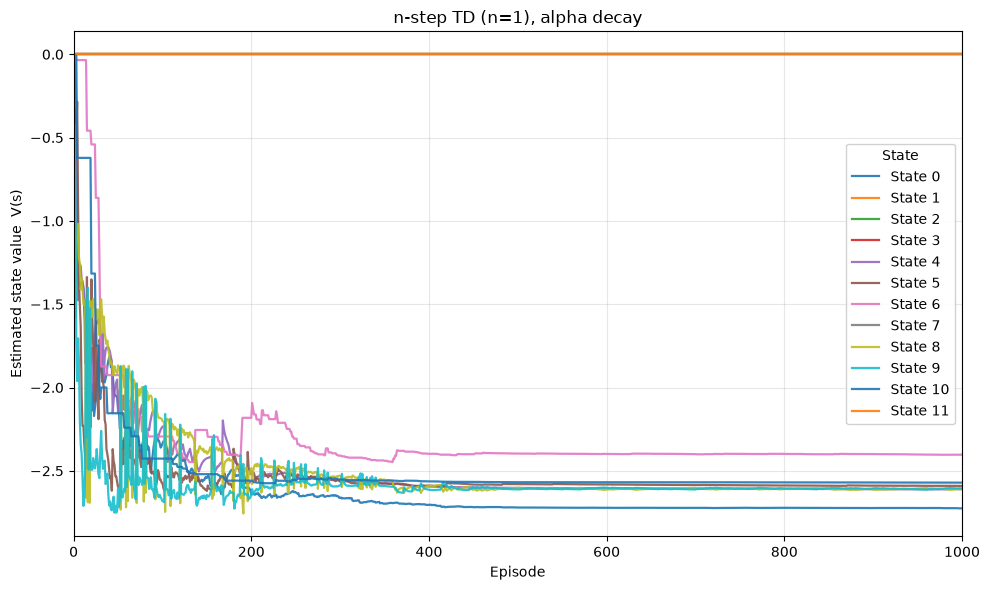

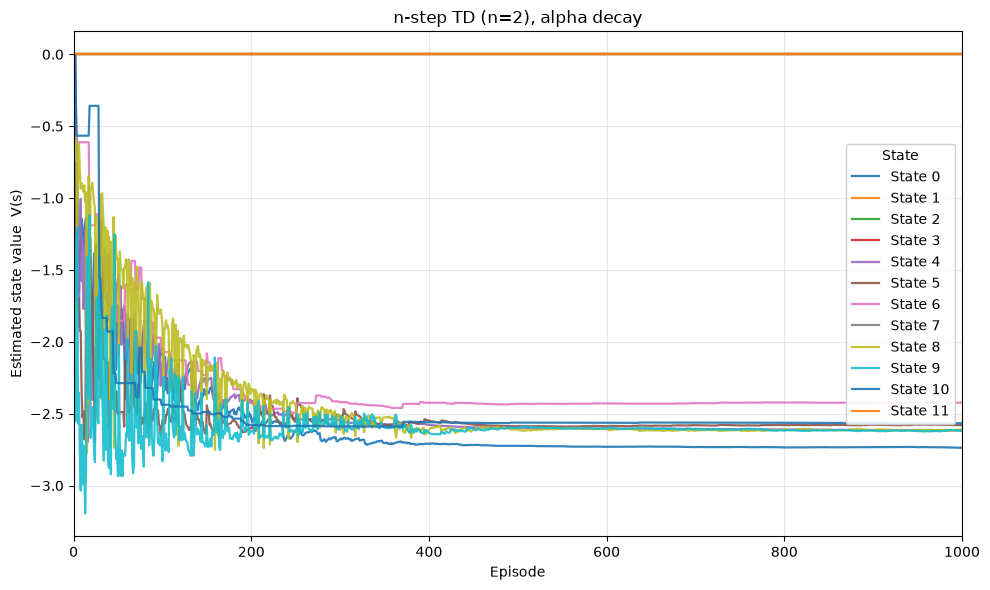

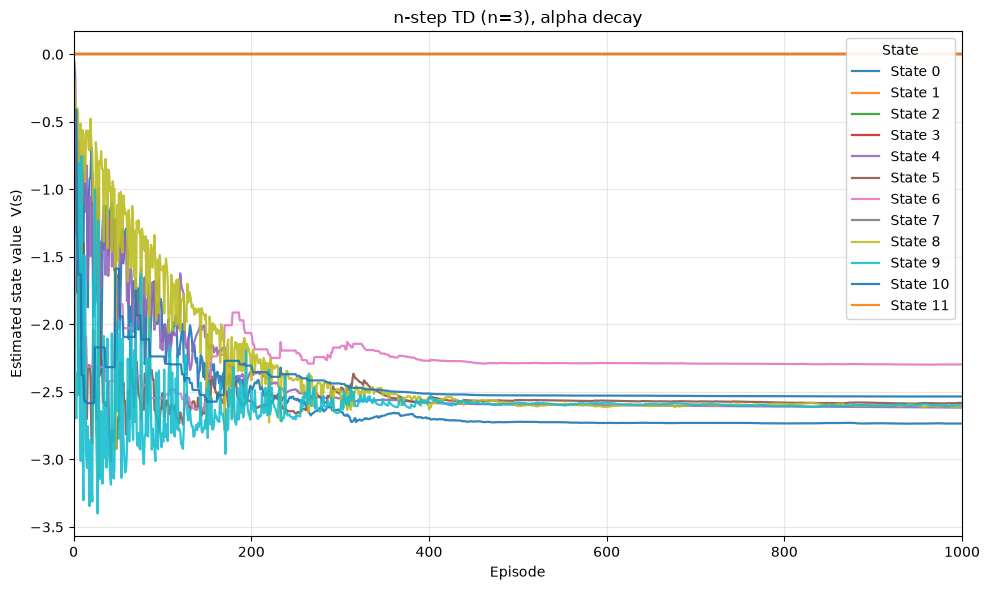

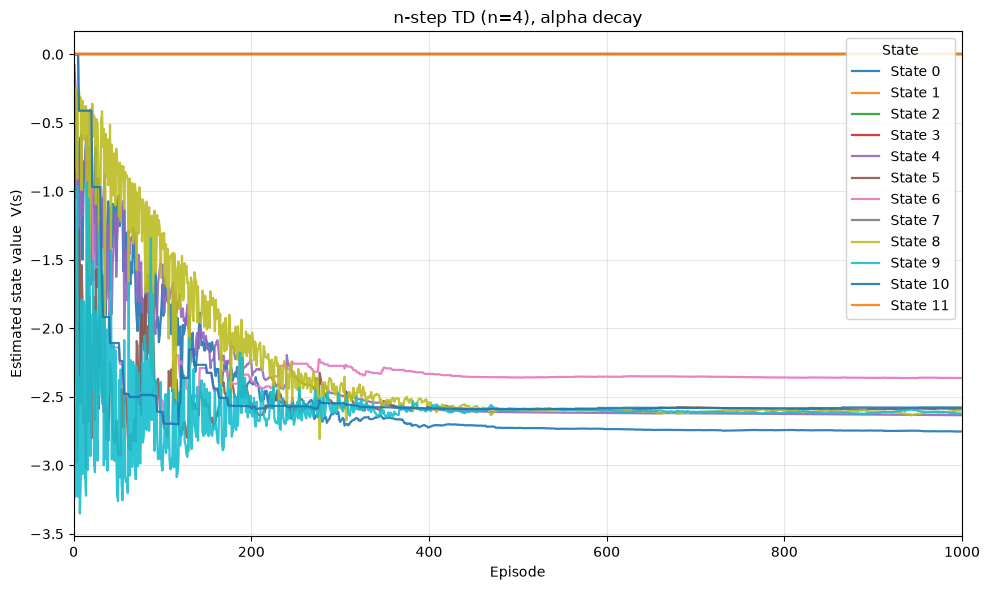

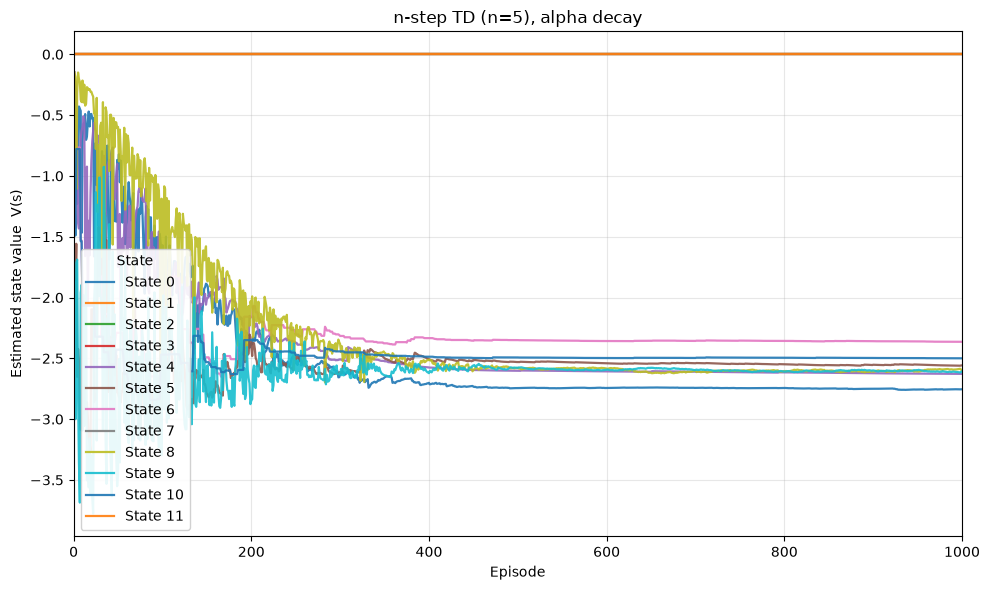

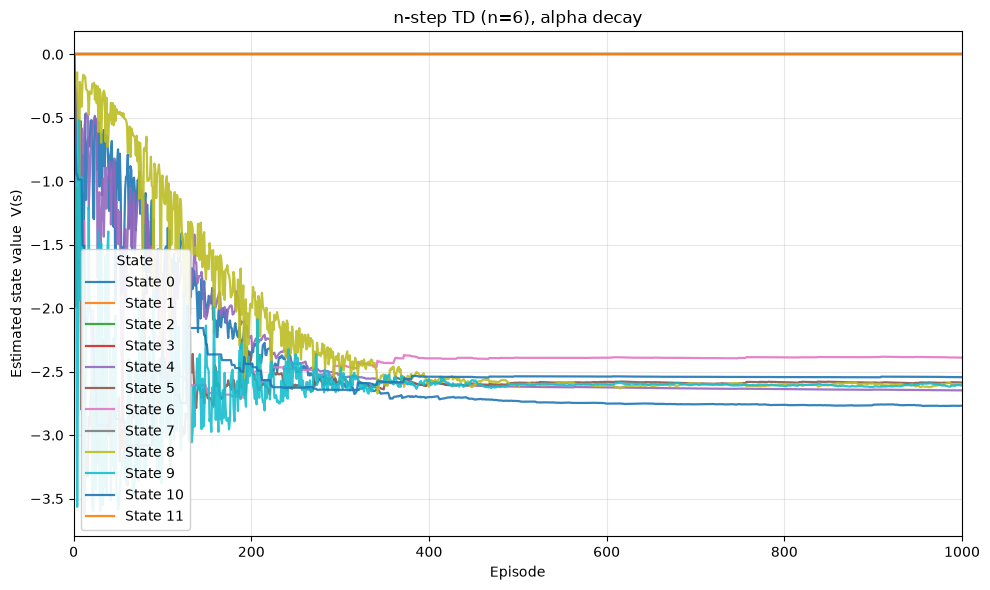

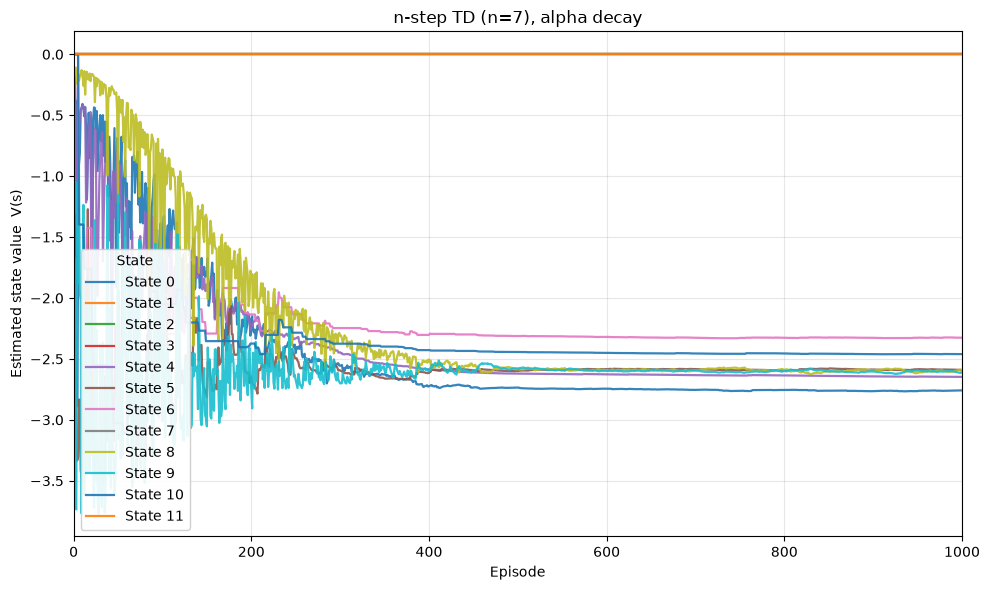

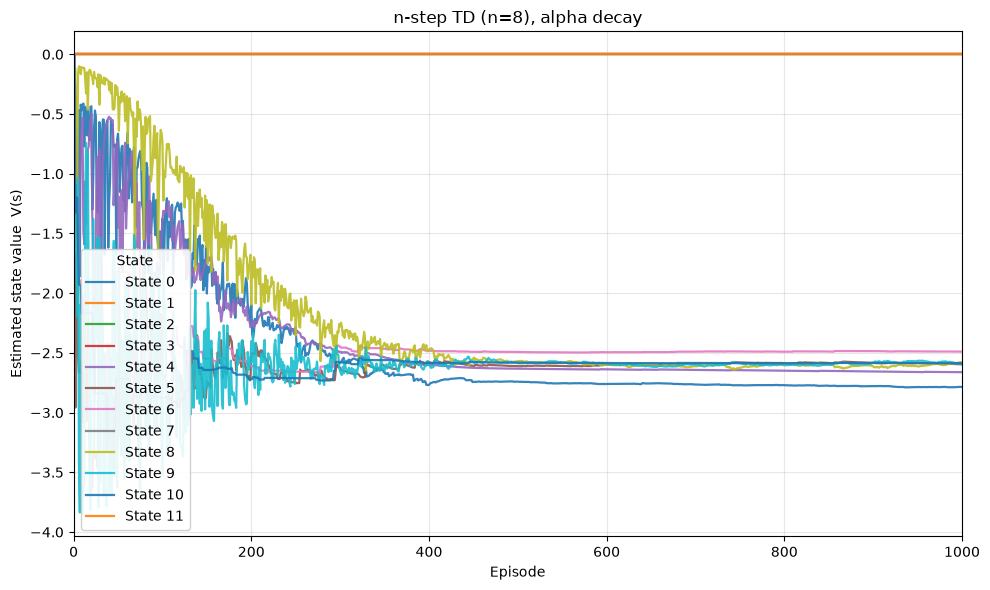

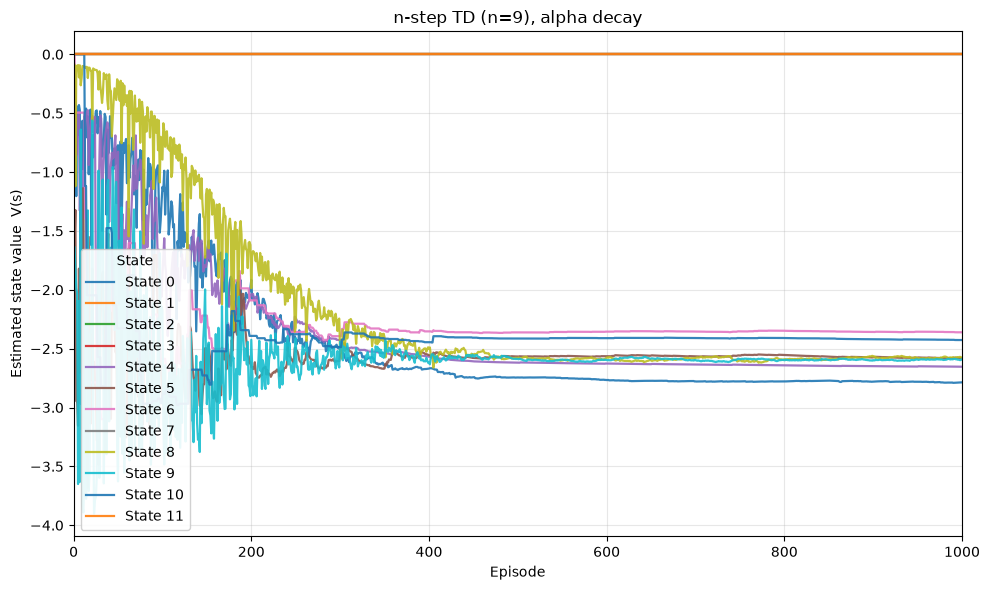

In [18]:
# n-step TD, n=3, book-style alpha decay
for n in range(1,10):
    V_ntd, V_track_ntd = ntd(bandit_walk_1, policy, gamma=0.99, n=n, alpha='decay',
                         init_alpha=0.5, min_alpha=1e-3, alpha_decay_ratio=0.5,
                         n_episodes=1000)
    fig, ax1 = plot_v_track(V_track_ntd, log_x=False, title=f"n-step TD (n={n}), alpha decay")

    plt.show()

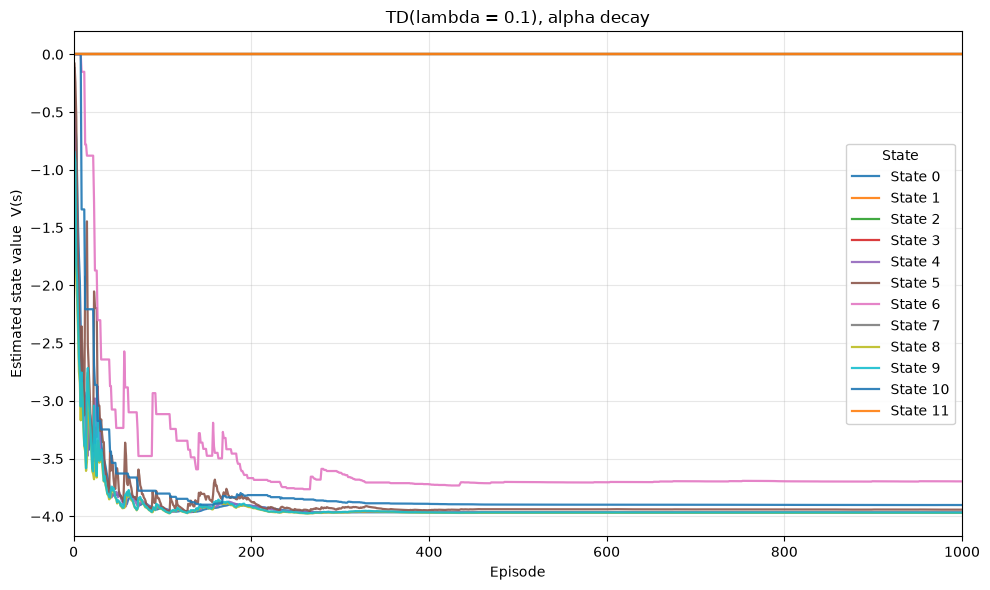

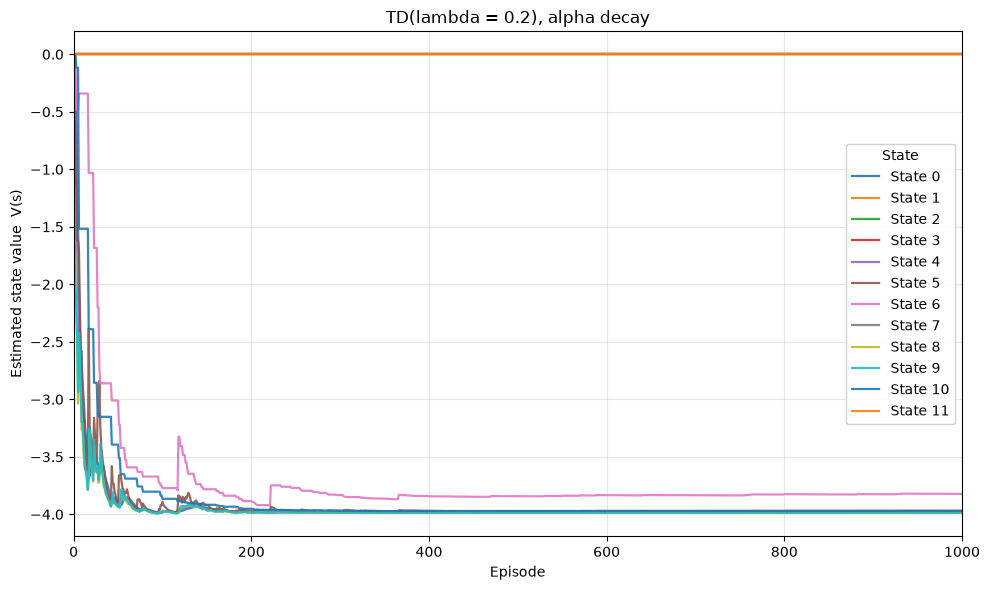

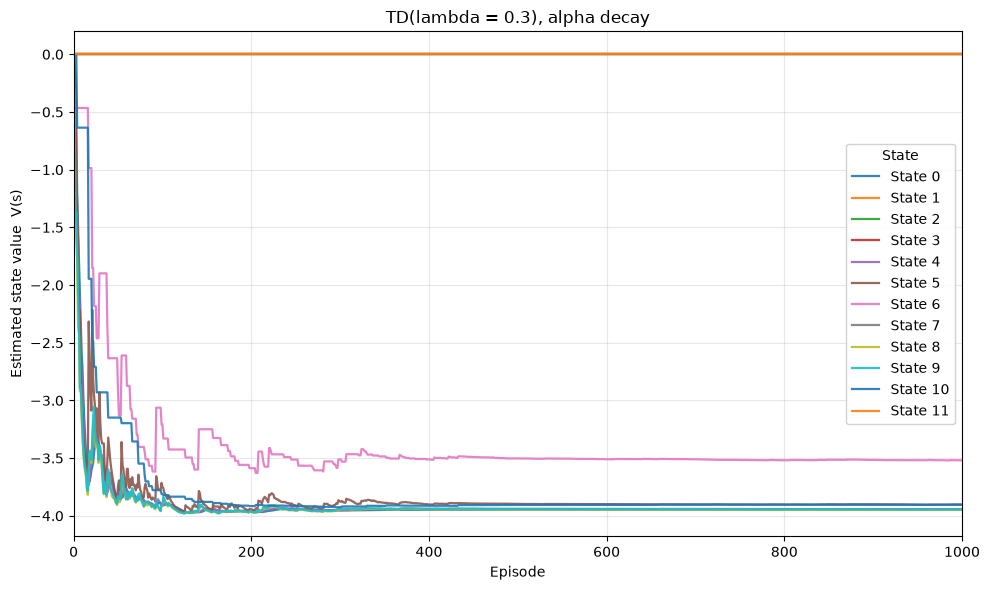

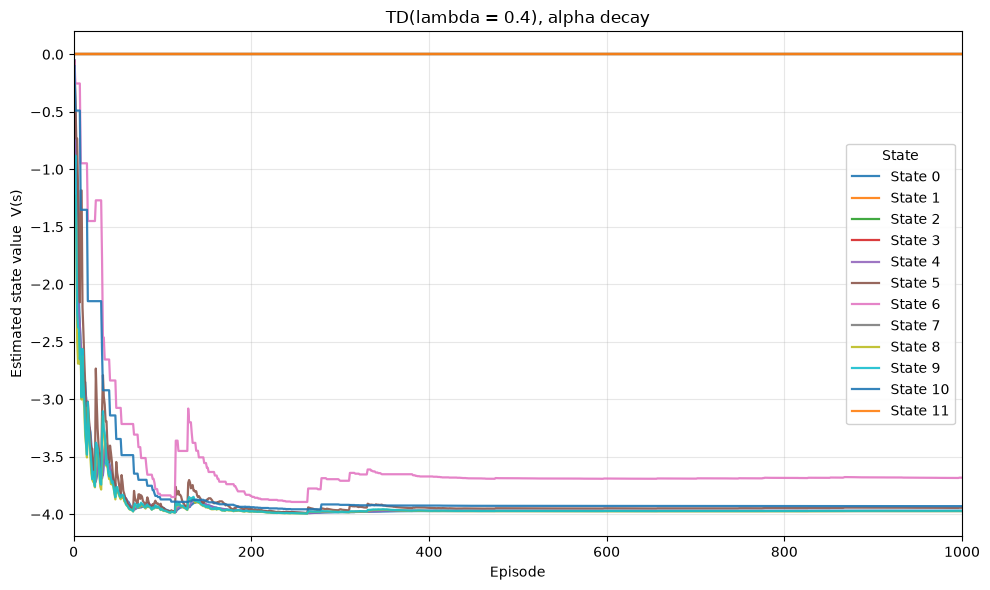

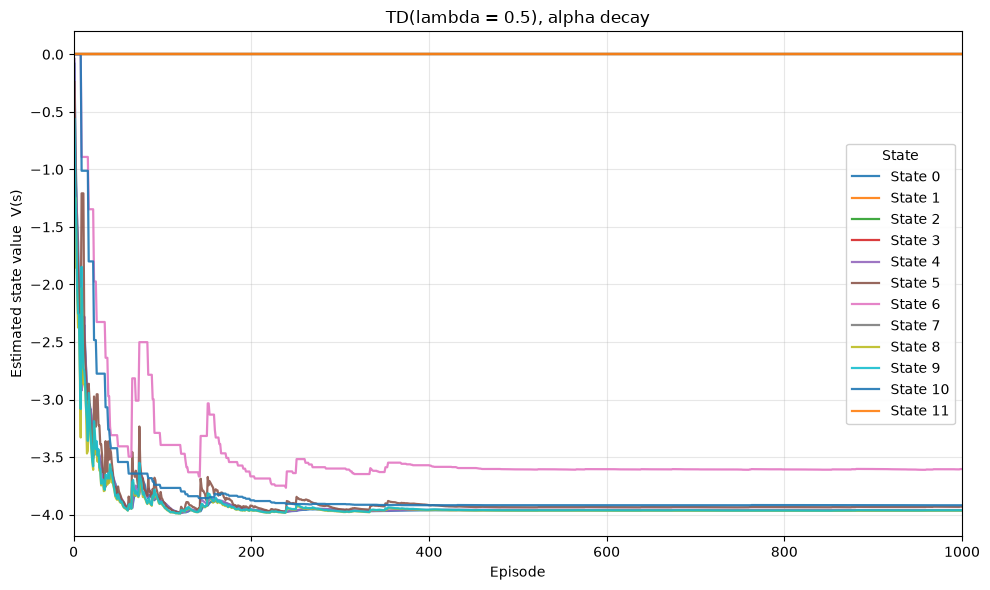

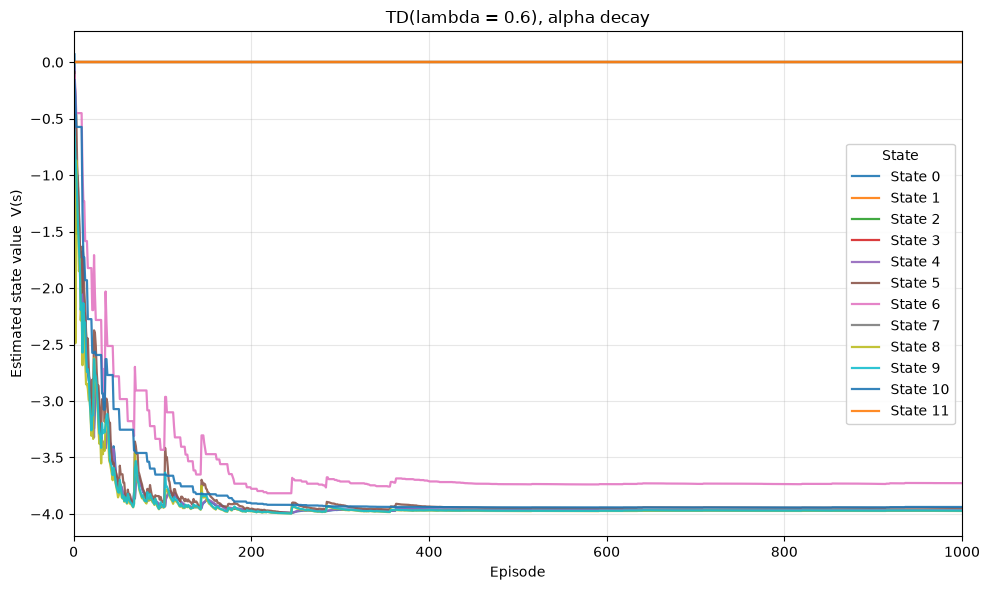

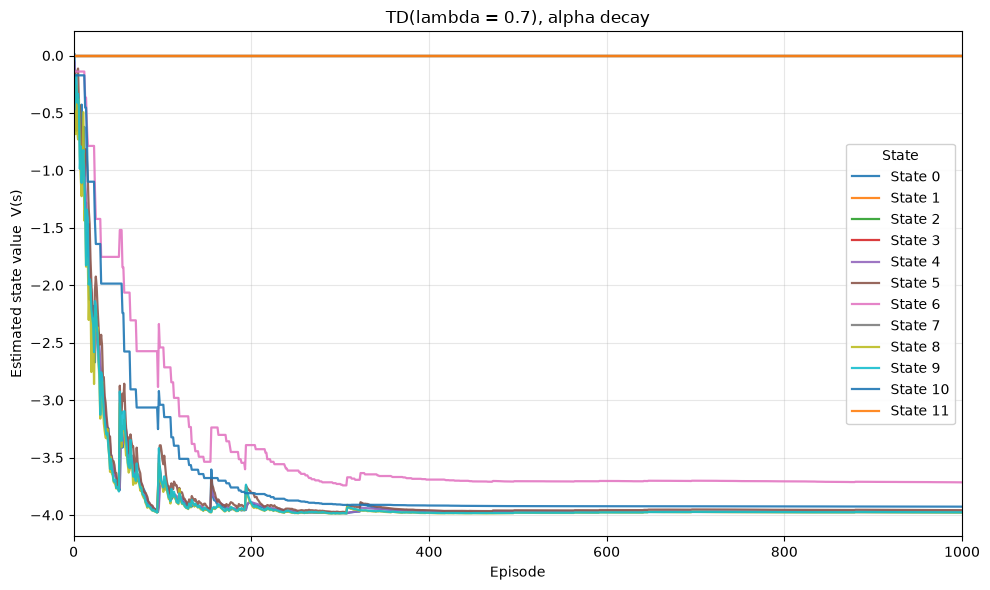

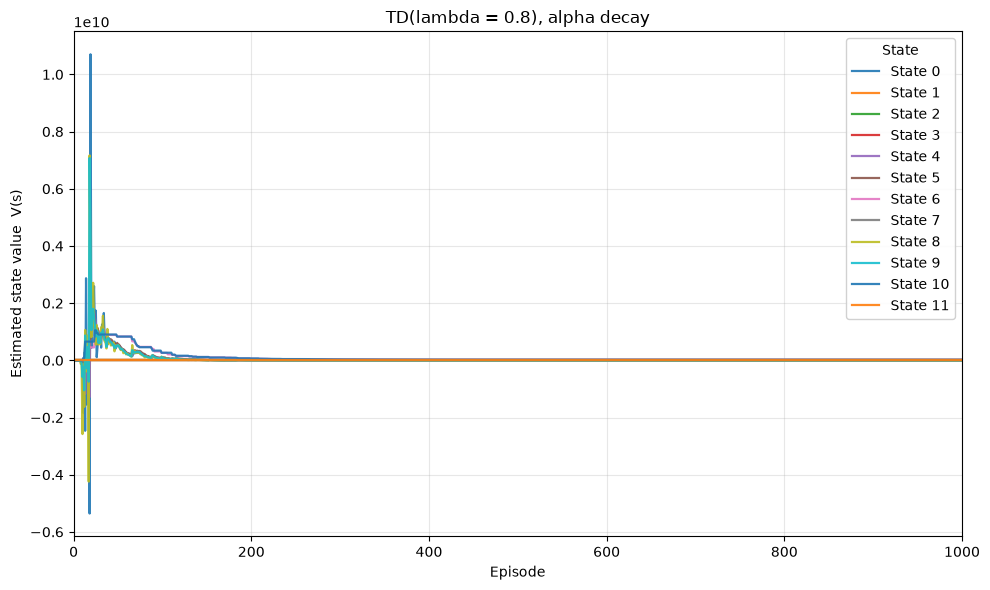

/tmp/ipykernel_122773/961630849.py:140: RuntimeWarning: overflow encountered in multiply
  V += alphas[e] * delta * E
/tmp/ipykernel_122773/961630849.py:140: RuntimeWarning: invalid value encountered in multiply
  V += alphas[e] * delta * E
/tmp/ipykernel_122773/961630849.py:131: RuntimeWarning: invalid value encountered in scalar subtract
  delta -= V[s_t]


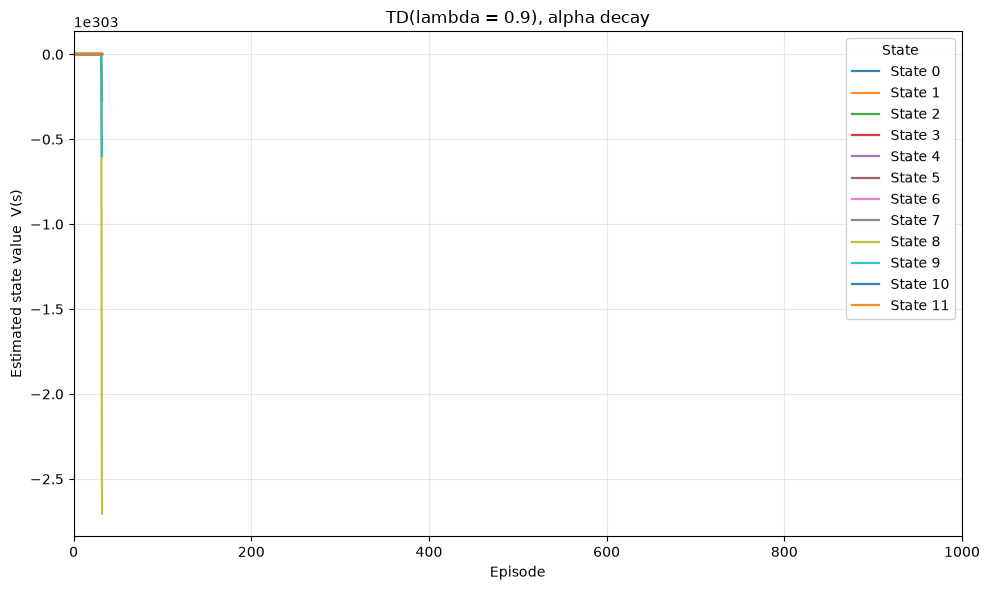

In [19]:


# TD(lambda), lambda=0.9, decaying alpha
for n in range(1,10):
    V_tdl, V_track_tdl = td_lambda(bandit_walk_1, policy, gamma=0.99, lambda_=n/10,
                                alpha='decay', init_alpha=0.5, min_alpha=1e-3,
                                alpha_decay_ratio=0.5, n_episodes=1000)

    fig, ax2 = plot_v_track(V_track_tdl, log_x=False, title=f"TD(lambda = {n/10}), alpha decay")
    plt.show()

In [1]:
import numpy as np

In [7]:
a = [[[1, 2, 3], [4, 5, 6], [7, 8, 9]], [[1.5, 2.5, 3.5], [4.5, 5.5, 6.5], [7.5, 8.5, 9.5]]]

arr = np.array(a)

In [8]:
arr.shape

(2, 3, 3)

In [9]:
np.sum(a)

np.float64(94.5)

In [15]:
np.sum(a, axis=(1, 2))

array([45. , 49.5])